In [9]:
!pip install shap


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\admin\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [1]:
!pip install pandas pyarrow scikit-learn xgboost shap matplotlib joblib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
    --------------------------------------- 0.8/48.9 MB 1.2 MB/s eta 0:00:42
    --------------------------------------- 1.0/48.9 MB 1.2 MB/s eta 0:00:39
   - -------------------------------------- 1.6/48.9 MB 1.4 MB/s eta 0:00:33
   - -------------------------------------- 1.8/48.9 MB 1.5 MB/s eta 0:00:32
   - -------------------------------------- 2.4/48.9 MB 1.7 MB/s eta 0:00:29
   -- ------------------------------------- 2.6/48.9 MB 1.7 MB/s eta 0:00:28
   -- ------------------------------------- 2.9/48.9 MB 1.6 MB/s eta 0:00:29
   -- ------------------------------------- 3.4/48.9 MB 1.7 MB/s eta 0:00:28
   -- ------------------------------------- 3.7/48.9 MB 1.7 MB/s eta 0:00:27
   --- --------------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\admin\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


# 02 – Mô hình rủi ro thanh lý: FinSurvival Borrow → Liquidated

Notebook này nối tiếp `finsurvival_borrow_liquidated_eda.ipynb` (cần chạy notebook đó trước để có `processed/train_labeled.parquet` và `processed/test_labeled.parquet`).

**Các bước**
1. Load dữ liệu đã gắn nhãn, thêm vùng đệm 30 ngày như bài báo, tách tập validation (3 tháng cuối của train)
2. Chuẩn bị đặc trưng (không dùng PCA)
3. Huấn luyện Logistic Regression và XGBoost, so với baseline của bài báo
4. Hiệu chuẩn xác suất (isotonic) – Brier score, reliability diagram
5. SHAP – các yếu tố ảnh hưởng nhiều nhất
6. Chia hạng A/B/C và tỷ lệ thanh lý thực tế theo hạng
7. Lưu mô hình + hash mô hình (để đưa lên ScoreOracle sau này)

**Cài thư viện:** `pip install pandas pyarrow scikit-learn xgboost shap matplotlib joblib`

**Baseline của bài báo (Bảng 8, borrow-liquidated, AUC):** LogReg 0,723 · XGBoost 0,732 · Elastic Net 0,723 · DeepHit 0,750 · Neural Net 0,748

In [2]:
import hashlib
import json
import os

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

pd.set_option("display.width", 160)
RNG = 42
PROCESSED = "processed"
OUT = "models"
os.makedirs(OUT, exist_ok=True)

PAPER_AUC = {"LogReg": 0.723, "XGBoost": 0.732, "DeepHit": 0.750}

## 1. Load dữ liệu, vùng đệm 30 ngày, tách validation

In [3]:
train_full = pd.read_parquet(os.path.join(PROCESSED, "train_labeled.parquet"))
test = pd.read_parquet(os.path.join(PROCESSED, "test_labeled.parquet"))

# Vùng đệm 30 ngày như bài báo (Mục 2.2): bỏ khoản vay trong 30 ngày cuối của mỗi tập
BUFFER = 30 * 86400
def apply_buffer(df):
    return df[df["timestamp"] <= df["timestamp"].max() - BUFFER].reset_index(drop=True)

train_full, test = apply_buffer(train_full), apply_buffer(test)
print(f"Sau vùng đệm: train {len(train_full):,} | test {len(test):,} | tổng {len(train_full) + len(test):,} (bài báo: 255.209)")

# Validation = 3 tháng cuối của tập train (dùng để chọn tham số, hiệu chuẩn, đặt ngưỡng hạng)
VAL_DAYS = 90
cut = train_full["timestamp"].max() - VAL_DAYS * 86400
train = train_full[train_full["timestamp"] <= cut].reset_index(drop=True)
val = train_full[train_full["timestamp"] > cut].reset_index(drop=True)

def span(df):
    t = pd.to_datetime(df["timestamp"], unit="s")
    return f"{t.min():%Y-%m-%d} -> {t.max():%Y-%m-%d}"

summary = pd.DataFrame({
    name: {"số dòng": len(df), "% lớp 1": round(100 * df["label"].mean(), 2), "thời gian": span(df)}
    for name, df in [("train", train), ("validation", val), ("test", test)]
}).T
display(summary)

Sau vùng đệm: train 161,467 | test 98,693 | tổng 260,160 (bài báo: 255.209)


,số dòng,% lớp 1,thời gian
train,138693,7.25,2020-12-01 -> 2022-02-28
validation,22774,3.45,2022-02-28 -> 2022-05-29
test,98693,1.28,2022-07-01 -> 2024-04-07


## 2. Chuẩn bị đặc trưng

- Bỏ cột định danh và cột kết quả (`id`, `timestamp`, `timeDiff`, `status`, `label`)
- Cột chữ: giữ 10 giá trị phổ biến nhất (theo tập train), còn lại gộp thành `Other`, rồi one-hot
- Cột số: điền thiếu bằng 0; với Logistic Regression thêm biến đổi `sign(x)·log1p(|x|)` vì số tiền lệch rất mạnh

In [4]:
NON_FEATURES = ["id", "timestamp", "timeDiff", "status", "label"]
feat_cols = [c for c in train.columns if c not in NON_FEATURES]
cat_cols = [c for c in feat_cols if not pd.api.types.is_numeric_dtype(train[c])]
num_cols = [c for c in feat_cols if c not in cat_cols]
print(f"{len(num_cols)} cột số, {len(cat_cols)} cột chữ: {cat_cols}")

TOP_CATS = {c: train[c].astype(str).value_counts().head(10).index.tolist() for c in cat_cols}


def build_X(df):
    X = df[num_cols].astype(float).fillna(0.0)
    for c in cat_cols:
        s = df[c].astype(str).where(df[c].astype(str).isin(TOP_CATS[c]), "Other")
        for v in TOP_CATS[c] + ["Other"]:
            X[f"{c}={v}"] = (s == v).astype(float)
    return X


X_tr, X_va, X_te = build_X(train), build_X(val), build_X(test)
y_tr, y_va, y_te = train["label"].values, val["label"].values, test["label"].values
print("Ma trận đặc trưng:", X_tr.shape, X_va.shape, X_te.shape)

slog = lambda X: np.sign(X) * np.log1p(np.abs(X))

105 cột số, 7 cột chữ: ['reserve', 'borrowRateMode', 'coinType', 'userReserveMode', 'userCoinTypeMode', 'userIsNew', 'isWeekend']
Ma trận đặc trưng: (138693, 142) (22774, 142) (98693, 142)


## 3. Huấn luyện mô hình

In [5]:
# Logistic Regression
logreg = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000, C=0.1))
logreg.fit(slog(X_tr), y_tr)

# XGBoost (dừng sớm theo AUC trên validation)
spw = (y_tr == 0).sum() / max((y_tr == 1).sum(), 1)
xgb = XGBClassifier(
    n_estimators=1000, learning_rate=0.05, max_depth=6, min_child_weight=5,
    subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw,
    eval_metric="auc", early_stopping_rounds=50, random_state=RNG, n_jobs=-1,
)
xgb.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
print("XGBoost best iteration:", xgb.best_iteration)

raw = {
    "LogReg": {s: logreg.predict_proba(slog(X))[:, 1] for s, X in [("val", X_va), ("test", X_te)]},
    "XGBoost": {s: xgb.predict_proba(X)[:, 1] for s, X in [("val", X_va), ("test", X_te)]},
}

XGBoost best iteration: 115


In [6]:
def metrics(y, p):
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p), "Brier": brier_score_loss(y, p)}

rows = []
for name, pr in raw.items():
    for split, y in [("val", y_va), ("test", y_te)]:
        rows.append({"model": name, "tập": split, **metrics(y, pr[split]), "tỷ lệ nền": y.mean()})
res = pd.DataFrame(rows)
res["AUC bài báo"] = res["model"].map(PAPER_AUC).where(res["tập"] == "test")
display(res.round(4))
print("PR-AUC của mô hình đoán ngẫu nhiên = tỷ lệ nền. Brier ở đây là của xác suất CHƯA hiệu chuẩn.")

,model,tập,ROC-AUC,PR-AUC,Brier,tỷ lệ nền,AUC bài báo
0,LogReg,val,0.8570,0.3303,0.1753,0.0345,NaN
1,LogReg,test,0.5920,0.0150,0.1822,0.0128,0.723
2,XGBoost,val,0.8696,0.2859,0.0503,0.0345,NaN
3,XGBoost,test,0.7867,0.0627,0.0392,0.0128,0.732


PR-AUC của mô hình đoán ngẫu nhiên = tỷ lệ nền. Brier ở đây là của xác suất CHƯA hiệu chuẩn.


## 4. Hiệu chuẩn xác suất

Mô hình được train với trọng số lớp nên xác suất bị thổi phồng. Hiệu chuẩn bằng isotonic regression trên tập validation, rồi kiểm tra trên test.

Lưu ý: tỷ lệ thanh lý ở test (khoảng 1,3%) thấp hơn nhiều so với validation, nên dù đã hiệu chuẩn, xác suất trên test vẫn có thể bị đánh giá cao. Đây là kết quả cần ghi vào báo cáo (RQ2).

,model,xác suất,Brier (test),xác suất TB dự đoán,tỷ lệ thực tế
0,LogReg,chưa hiệu chuẩn,0.1822,0.2572,0.0128
1,LogReg,đã hiệu chuẩn,0.0247,0.0409,0.0128
2,XGBoost,chưa hiệu chuẩn,0.0392,0.1329,0.0128
3,XGBoost,đã hiệu chuẩn,0.0139,0.0257,0.0128


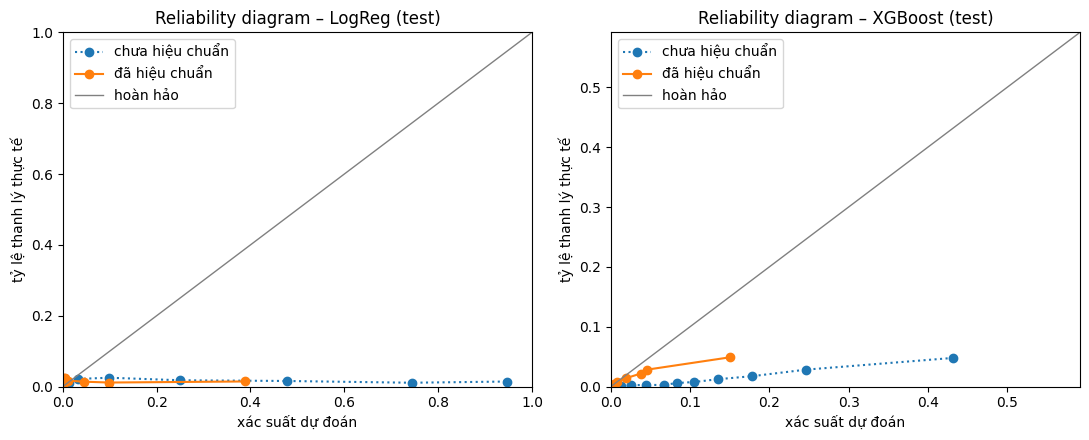

In [7]:
calibrators, cal = {}, {}
for name, pr in raw.items():
    iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(pr["val"], y_va)
    calibrators[name] = iso
    cal[name] = {"val": iso.predict(pr["val"]), "test": iso.predict(pr["test"])}

rows = []
for name in raw:
    for kind, src in [("chưa hiệu chuẩn", raw), ("đã hiệu chuẩn", cal)]:
        p = src[name]["test"]
        rows.append({"model": name, "xác suất": kind, "Brier (test)": brier_score_loss(y_te, p),
                     "xác suất TB dự đoán": p.mean(), "tỷ lệ thực tế": y_te.mean()})
display(pd.DataFrame(rows).round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, name in zip(axes, raw):
    for kind, src, ls in [("chưa hiệu chuẩn", raw, ":"), ("đã hiệu chuẩn", cal, "-")]:
        fp, mp = calibration_curve(y_te, src[name]["test"], n_bins=10, strategy="quantile")
        ax.plot(mp, fp, ls, marker="o", label=kind)
    lim = max(0.05, float(np.max(cal[name]["test"])))
    ax.plot([0, lim], [0, lim], color="grey", lw=1, label="hoàn hảo")
    ax.set_xlim(0, lim); ax.set_ylim(0, lim)
    ax.set_title(f"Reliability diagram – {name} (test)")
    ax.set_xlabel("xác suất dự đoán"); ax.set_ylabel("tỷ lệ thanh lý thực tế"); ax.legend()
plt.tight_layout(); plt.show()

In [11]:
%pip install shap

  Using cached shap-0.54.1-cp312-abi3-win_amd64.whl.metadata (23 kB)
  Using cached slicer-0.0.8-py3-none-any.whl.metadata (4.0 kB)
Using cached shap-0.54.1-cp312-abi3-win_amd64.whl (751 kB)
Using cached slicer-0.0.8-py3-none-any.whl (15 kB)

   ---------------------------------------- 0/2 [slicer]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ----------------

## 5. SHAP – yếu tố ảnh hưởng nhiều nhất (XGBoost)

,mean |SHAP|
userLiquidationCount,0.4015
userDepositAvgAmountETH,0.2767
userSecondsSinceFirstTransaction,0.2081
priceInUSD,0.1447
userDepositAvgAmountUSD,0.1376
userBorrowCount,0.1297
sinDayOfYear,0.1246
userBorrowAvgAmountETH,0.1184
userDepositCount,0.1140
marketLiquidationAvgAmountETH,0.1099


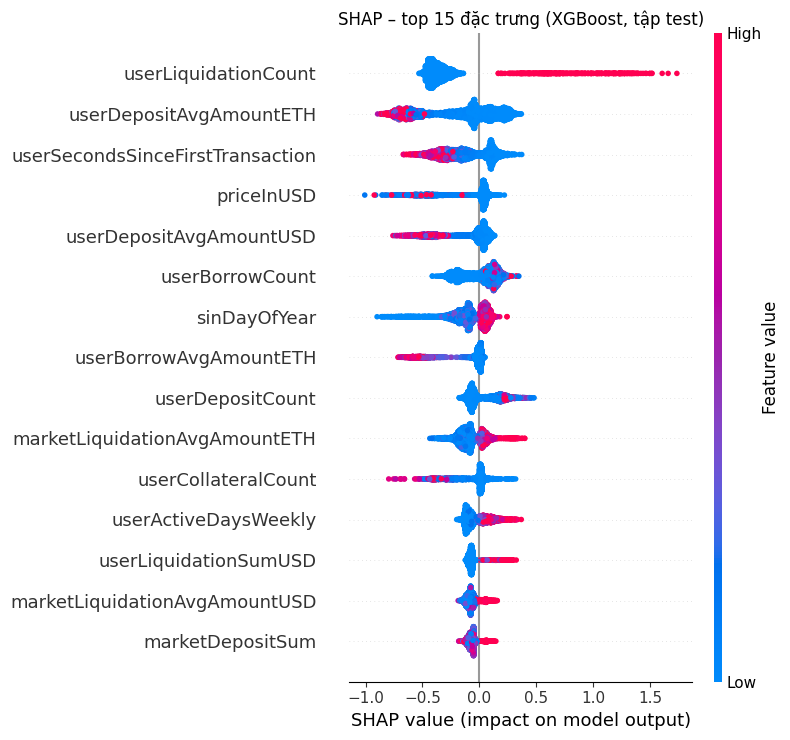

In [12]:
import shap

sample = X_te.sample(min(5000, len(X_te)), random_state=RNG)
explainer = shap.TreeExplainer(xgb)
sv = explainer.shap_values(sample)

imp = pd.Series(np.abs(sv).mean(axis=0), index=sample.columns).sort_values(ascending=False)
display(imp.head(15).rename("mean |SHAP|").to_frame().round(4))

shap.summary_plot(sv, sample, max_display=15, show=False)
plt.title("SHAP – top 15 đặc trưng (XGBoost, tập test)")
plt.tight_layout(); plt.show()

## 6. Chia hạng A/B/C

Ngưỡng đặt theo **phân vị điểm số trên tập validation** (70% thấp nhất → A, 20% tiếp → B, 10% cao nhất → C), rồi áp nguyên ngưỡng đó lên test. Dùng phân vị thay vì xác suất tuyệt đối vì tỷ lệ nền thay đổi mạnh giữa hai giai đoạn.

Mô hình dùng để chia hạng (AUC validation cao nhất): XGBoost


,tập,hạng,số khoản vay,% khoản vay,tỷ lệ thanh lý (%)
0,validation,A,15942,70.00,0.70
1,validation,B,4554,20.00,4.50
2,validation,C,2278,10.00,20.63
3,test,A,71675,72.62,0.54
4,test,B,19973,20.24,2.49
5,test,C,7045,7.14,5.35


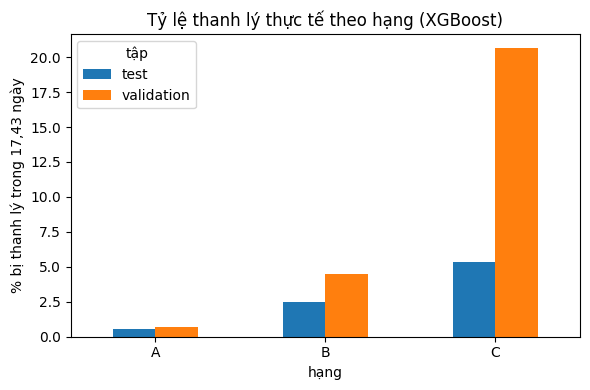

Hạng C chiếm 7.1% khoản vay nhưng chứa 29.9% số ca bị thanh lý (test).


In [13]:
TIER_SPLIT = [0.70, 0.90]   # A: 0-70%, B: 70-90%, C: 90-100%
BEST = max(raw, key=lambda n: roc_auc_score(y_va, raw[n]["val"]))
print("Mô hình dùng để chia hạng (AUC validation cao nhất):", BEST)

# Dùng điểm thô (chưa hiệu chuẩn) để chia hạng: cùng thứ tự với điểm hiệu chuẩn nhưng không bị "bậc thang" như isotonic
thr_raw = np.quantile(raw[BEST]["val"], TIER_SPLIT)

def tier_of(p):
    return np.select([p <= thr_raw[0], p <= thr_raw[1]], ["A", "B"], default="C")

rows = []
for split, df_y, p in [("validation", y_va, raw[BEST]["val"]), ("test", y_te, raw[BEST]["test"])]:
    t = tier_of(p)
    for k in ["A", "B", "C"]:
        m = t == k
        rows.append({"tập": split, "hạng": k, "số khoản vay": int(m.sum()), "% khoản vay": 100 * m.mean(),
                     "tỷ lệ thanh lý (%)": 100 * df_y[m].mean() if m.any() else np.nan})
tiers = pd.DataFrame(rows)
display(tiers.round(2))

piv = tiers.pivot(index="hạng", columns="tập", values="tỷ lệ thanh lý (%)")
ax = piv.plot.bar(rot=0, figsize=(6, 4))
ax.set_ylabel("% bị thanh lý trong 17,43 ngày"); ax.set_title(f"Tỷ lệ thanh lý thực tế theo hạng ({BEST})")
plt.tight_layout(); plt.show()

c_share = tiers.query("tập == 'test' and hạng == 'C'")["số khoản vay"].iloc[0] / len(y_te)
liq_in_c = y_te[tier_of(raw[BEST]["test"]) == "C"].sum() / max(y_te.sum(), 1)
print(f"Hạng C chiếm {100 * c_share:.1f}% khoản vay nhưng chứa {100 * liq_in_c:.1f}% số ca bị thanh lý (test).")

## 7. Lưu mô hình và hash (cho ScoreOracle)

In [ ]:
bundle = {
    "model_name": BEST,
    "model": xgb if BEST == "XGBoost" else logreg,
    "calibrator": calibrators[BEST],
    "num_cols": num_cols, "cat_cols": cat_cols, "top_cats": TOP_CATS,
    "tier_thresholds_raw": thr_raw.tolist(), "tier_split": TIER_SPLIT,
    "log_transform": BEST == "LogReg",
}
path = os.path.join(OUT, "liquidation_model.joblib")
joblib.dump(bundle, path)

model_hash = "0x" + hashlib.sha256(open(path, "rb").read()).hexdigest()
meta = {"model_file": path, "model_hash_sha256": model_hash, "model_version": 1, "model_name": BEST,
        "test_metrics": {k: round(float(v), 4) for k, v in metrics(y_te, raw[BEST]["test"]).items()},
        "tier_thresholds_raw": thr_raw.tolist()}
json.dump(meta, open(os.path.join(OUT, "model_meta.json"), "w"), indent=2)
res.round(4).to_csv(os.path.join(OUT, "results_metrics.csv"), index=False)
tiers.round(4).to_csv(os.path.join(OUT, "results_tiers.csv"), index=False)
print(json.dumps(meta, indent=2))

{
  "model_file": "models\\liquidation_model.joblib",
  "model_hash_sha256": "0x9dab4ac6c7254473599ea4b6259512651c36a73344611a4b89e86559d72c0e6e",
  "model_version": 1,
  "model_name": "XGBoost",
  "test_metrics": {
    "ROC-AUC": 0.7867,
    "PR-AUC": 0.0627,
    "Brier": 0.0392
  },
  "tier_thresholds_raw": [
    0.1657916486263275,
    0.34257663190364857
  ]
}


: 

## Ghi chú cho báo cáo

- **RQ1:** bảng ở mục 6 – tỷ lệ thanh lý tăng dần A < B < C chứng tỏ điểm số phân tách được rủi ro.
- **So với bài báo:** bảng ở mục 3 (cột AUC bài báo). Bài báo dùng PCA cho LogReg và tham số cố định cho XGBoost.
- **RQ2 (độ ổn định theo thời gian):** chênh lệch AUC/Brier giữa validation và test, và reliability diagram ở mục 4.
- `models/model_meta.json` chứa `model_hash_sha256` để đăng ký vào contract ScoreOracle.